##1.Data Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global plot aesthetics for better readability
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

# Load the crime dataset into a pandas DataFrame
df = pd.read_csv('crime.csv')

# Output the total number of rows and columns to verify the data size
print("Dataset shape:", df.shape)

# Display the first few rows of the dataset
print(df.head())

Dataset shape: (970, 52)
  Sl. No        State/UT               District  \
0      1  Andhra Pradesh  Alluri Sitharama Raju   
1      2  Andhra Pradesh             Anakapalli   
2      3  Andhra Pradesh           Anantapuramu   
3      4  Andhra Pradesh              Annamayya   
4      5  Andhra Pradesh                Bapatla   

   A. Offences under I.T.Act - Tampering computer source documents (Sec.65) - Col. ( 3)  \
0                                                  0                                      
1                                                  0                                      
2                                                  0                                      
3                                                  0                                      
4                                                  0                                      

   A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Co

## 2. Initial Inspection

In [2]:
# Display a concise summary of the DataFrame, including column names, non-null counts, and data types
df.info()

# Print a blank line to separate the outputs for better readability
print()

# Calculate and display the total number of missing (NaN) values present in each column
print("Missing values per column:")
print(df.isnull().sum())
print()

# Count and display the total number of exact duplicate rows in the dataset
print("Number of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 52 columns):
 #   Column                                                                                                                                                                                                                                               Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                                                               --------------  ----- 
 0   Sl. No                                                                                                                                                                                                                                               970 non-null    object
 1   State/UT                                                               

## 3. Data Cleaning
### 3.1 Handling Missing Values

In [3]:
# Impute missing values in continuous numeric columns using their respective medians
columns_to_impute = [
    'A. Offences under I.T.Act - Cyber Terrorism (Sec.66 F) - Col. ( 12)',
    'C. Offences under SLL (Involving Communication Devices as Medium/Target) r/w IT Act. - Gambling Act (Online Gambling) - Col. ( 45)',
    'Total Cyber Crimes (A+B+C) - Col. ( 51)'
]

for col in columns_to_impute:
    median_val = df[col].median()
    # Count missing values before imputation to log what is being changed
    n_missing = df[col].isnull().sum()
    # Impute (fill) any missing values in the column with its calculated median
    df[col] = df[col].fillna(median_val)
    print(f"{col[:30]}... : filled {n_missing} missing values with median = {median_val:.2f}")

# Check if any missing values remain elsewhere in the broader dataset
print("\nMissing values remaining:", df.isnull().sum().sum())

A. Offences under I.T.Act - Cy... : filled 0 missing values with median = 0.00
C. Offences under SLL (Involvi... : filled 0 missing values with median = 0.00
Total Cyber Crimes (A+B+C) - C... : filled 0 missing values with median = 17.00

Missing values remaining: 0


### 3.2 Removing Duplicate Rows



In [4]:
# Remove any exact duplicate rows and log the total number dropped
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

# Record the total number of rows after the drop operation
after = len(df)
print(f"Removed {before - after} duplicate rows.")

# Print the final shape of the dataset to confirm its current dimensions.
print(f"Dataset shape after removing duplicates: {df.shape}")

Removed 0 duplicate rows.
Dataset shape after removing duplicates: (970, 52)


### 3.3 Handling Outliers

In [5]:
# Define a helper function to calculate Interquartile Range (IQR) boundaries
def iqr_bounds(series):
    # Calculate the 25th percentile (Q1) and 75th percentile (Q3)
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

# Select continuous numeric columns from the crime dataset to check for outliers
crime_cols_to_check = [
    'A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)',
    'Total Cyber Crimes (A+B+C) - Col. ( 51)'
]

# Detect extreme values in numerical columns and cap them at IQR boundaries (winsorization)
for col in crime_cols_to_check:
    # Unpack the calculated lower and upper bounds for the current column
    low, high = iqr_bounds(df[col])
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()

    # Using string slicing col[:40] just to keep the print statement readable in the console
    print(f"{col[:40]}...: IQR bounds = [{low:.2f}, {high:.2f}], outliers found = {n_outliers}")

    # Apply winsorization: cap any extreme values at the exact lower and upper boundaries.
    df[col] = df[col].clip(lower=low, upper=high)

print("\nOutliers capped to IQR bounds (winsorized).")

# Display summary statistics to verify the final data distribution.
# Notice that the 'max' values will now perfectly align with the calculated upper bounds.
print(df[crime_cols_to_check].describe())

A. Offences under I.T.Act - Computer Rel...: IQR bounds = [-16.50, 27.50], outliers found = 141
Total Cyber Crimes (A+B+C) - Col. ( 51)...: IQR bounds = [-73.50, 130.50], outliers found = 77

Outliers capped to IQR bounds (winsorized).
       A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)  \
count                                         970.000000                                                                                         
mean                                            6.845876                                                                                         
std                                            10.142036                                                                                         
min                                             0.000000                                                                                         
25%                               

## 4. Exploratory Data Analysis (EDA)
### 4.1 Descriptive Statistics

In [6]:
# View basic statistical details like mean, min, and max for numerical columns
print(df.describe())

       A. Offences under I.T.Act - Tampering computer source documents (Sec.65) - Col. ( 3)  \
count                                         970.000000                                      
mean                                            0.134021                                      
std                                             1.309084                                      
min                                             0.000000                                      
25%                                             0.000000                                      
50%                                             0.000000                                      
75%                                             0.000000                                      
max                                            26.000000                                      

       A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)  

### 4.2 Correlation Analysis





In [7]:
# Calculate and display the correlation matrix for specific numerical columns
# Using primary crime categories from the dataset
numeric_cols = [
    'A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)',
    'B. Offences under IPC (Involving Communication Devices as Medium/Target) r/w IT Act. - Fraud (Sec.420 r/w Sec.465,468-471 IPC) - Fraud (Sec.420 r/w Sec.465,468-471 IPC) (Total) (Col.29 to 33) - Col. ( 28)',
    'Total Cyber Crimes (A+B+C) - Col. ( 51)'
]

corr_matrix = df[numeric_cols].corr()
print(corr_matrix.round(5))

                                                    A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)  \
A. Offences under I.T.Act - Computer Related Of...                                            1.00000                                                                                         
B. Offences under IPC (Involving Communication ...                                            0.12782                                                                                         
Total Cyber Crimes (A+B+C) - Col. ( 51)                                                       0.63043                                                                                         

                                                    B. Offences under IPC (Involving Communication Devices as Medium/Target) r/w IT Act. - Fraud (Sec.420 r/w Sec.465,468-471 IPC) - Fraud (Sec.420 r/w Sec.465,468-471 IPC) (Total) (Col.2

### 4.3 Average Cyber Crimes and IT Offences by State



In [ ]:
# Group by State to calculate average crime metrics, sorting by highest average total crimes
state_summary = df.groupby('State/UT').agg(
    Avg_Total_Crimes=('Total Cyber Crimes (A+B+C) - Col. ( 51)', 'mean'),
    Avg_IT_Offences=('A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)', 'mean'),
    District_Count=('District', 'count')
).round(1).sort_values('Avg_Total_Crimes', ascending=False)

# Display the top 10 states *
print(state_summary.head(10))

                 Avg_Total_Crimes  Avg_IT_Offences  District_Count
State/UT                                                          
Total Districts              89.0             19.9              36
Telangana                    85.5              2.0              30
Uttar Pradesh                73.4             20.3              78
Maharashtra                  58.2              6.2              49
Karnataka                    56.6             21.2              38
Andhra Pradesh               55.7              7.3              28
Odisha                       52.1              4.1              37
Tamil Nadu                   39.6             14.9              49
Rajasthan                    38.1              5.2              48
Jharkhand                    35.4             16.5              26


### 4.4 Interactive Data Visualization

Dataset Shape: (970, 52)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 52 columns):
 #   Column                                                                                                                                                                                                                                               Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                                                               --------------  ----- 
 0   Sl. No                                                                                                                                                                                                                                               970 non-null    object
 1   State/UT                                      

/tmp/ipykernel_666/889235787.py:35: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




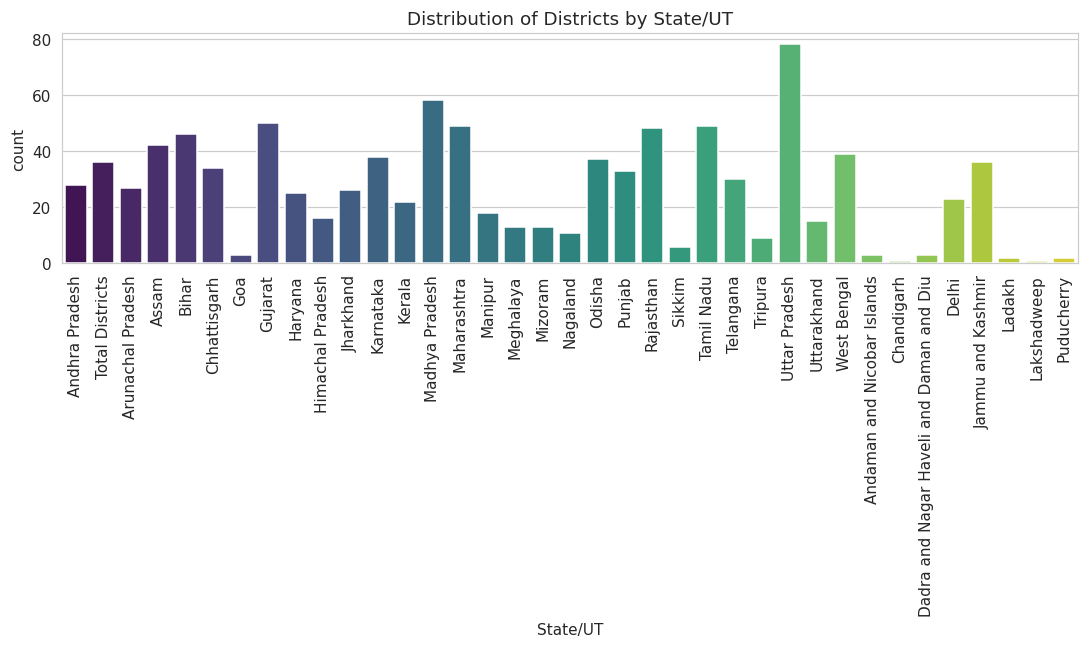

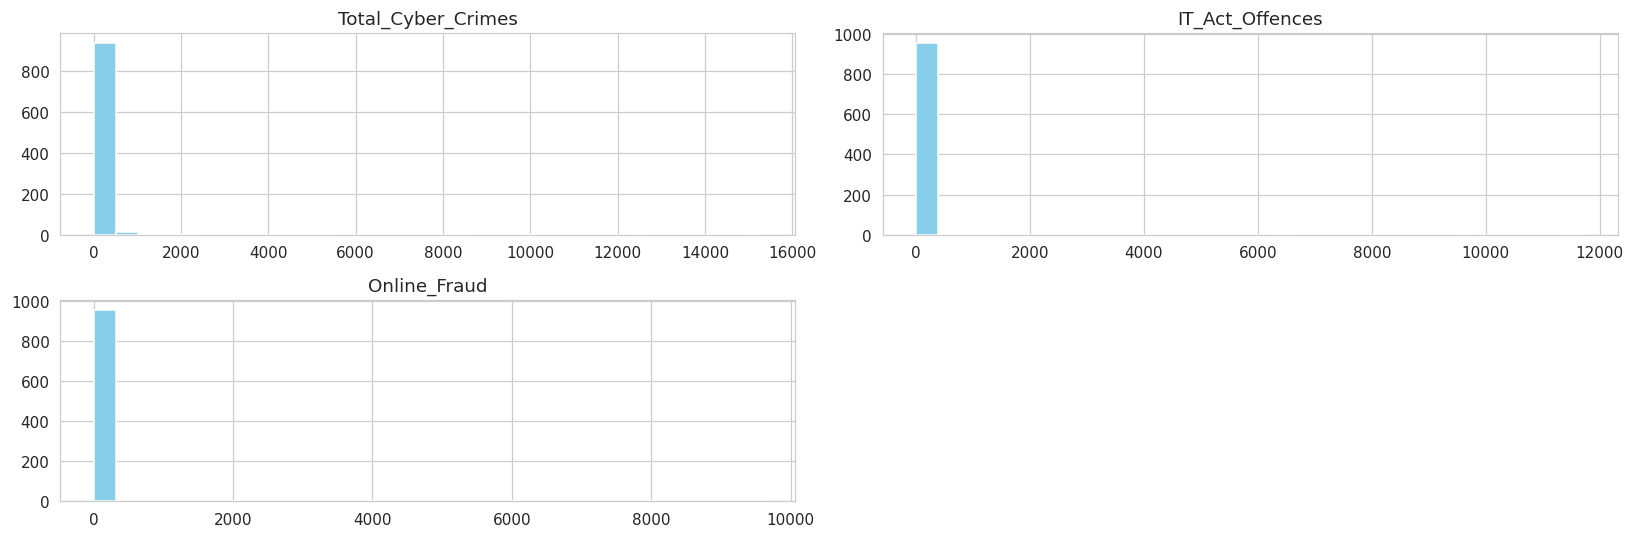

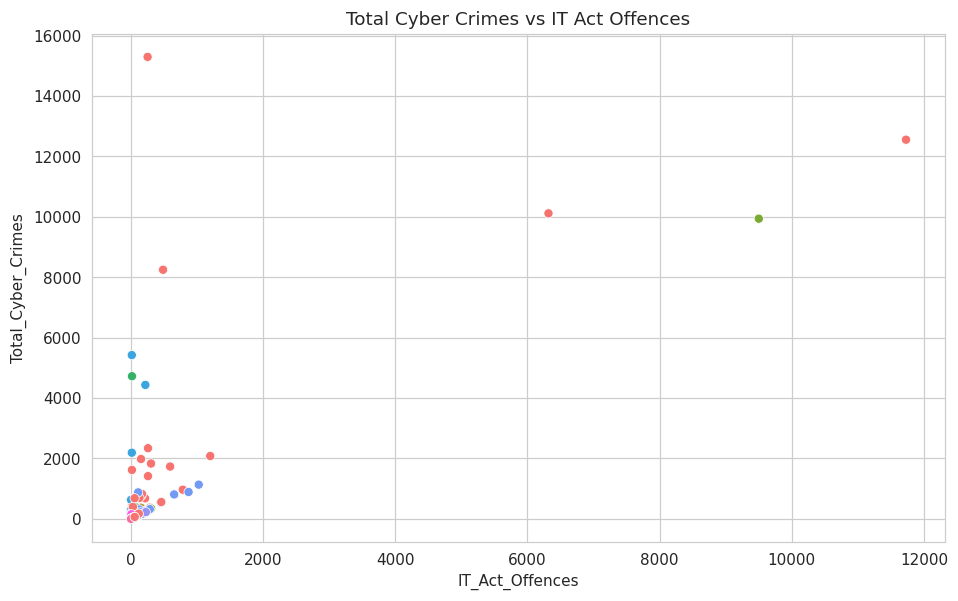

/tmp/ipykernel_666/889235787.py:53: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




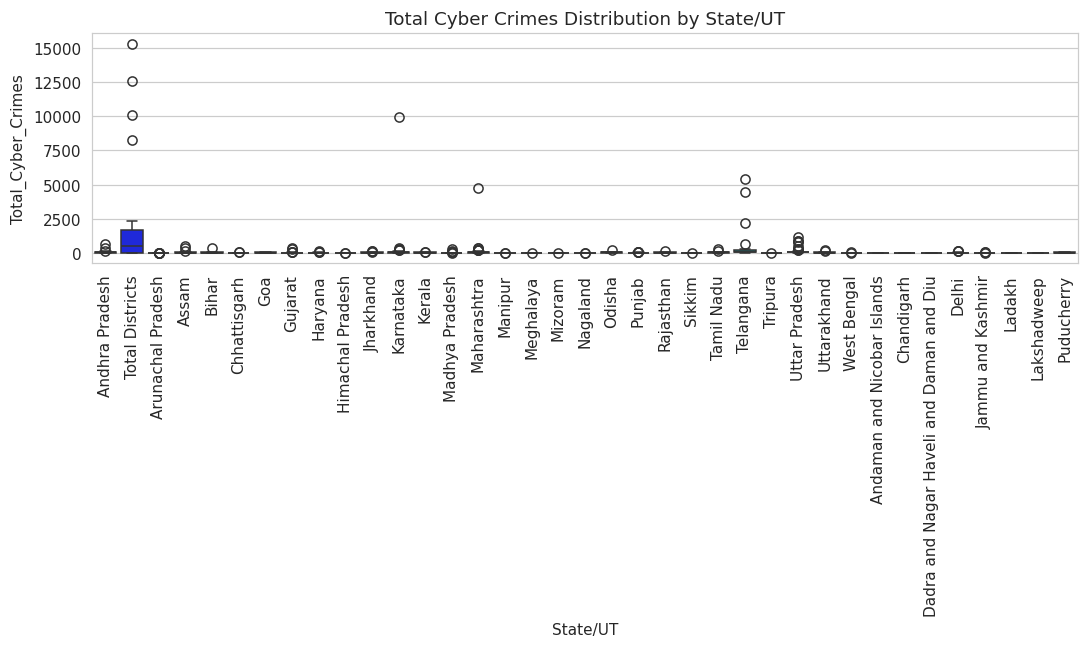

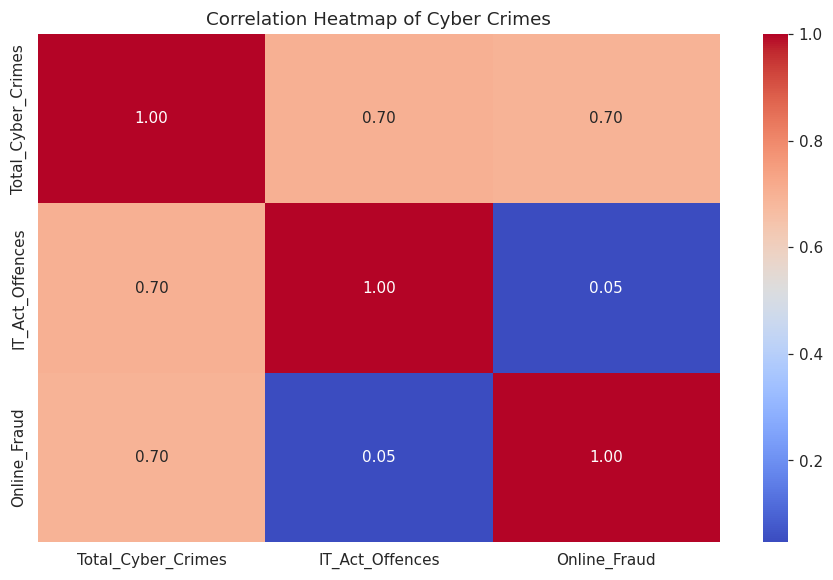

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.rcParams['figure.figsize']=(10,6)

# Load the dataset
df = pd.read_csv('crime.csv')

# Rename the extremely long NCRB columns to simple names for clean visualizations
df = df.rename(columns={
    'A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)': 'IT_Act_Offences',
    'B. Offences under IPC (Involving Communication Devices as Medium/Target) r/w IT Act. - Fraud (Sec.420 r/w Sec.465,468-471 IPC) - Fraud (Sec.420 r/w Sec.465,468-471 IPC) (Total) (Col.29 to 33) - Col. ( 28)': 'Online_Fraud',
    'Total Cyber Crimes (A+B+C) - Col. ( 51)': 'Total_Cyber_Crimes'
})

df.head()
print("Dataset Shape:", df.shape)
df.info()
print(df.dtypes)
df.describe()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Drop duplicates if any
df = df.drop_duplicates()

# 1. Categorical Countplots (Using State/UT)
categorical_cols = ['State/UT']

for col in categorical_cols:
    plt.figure(figsize=(10,6))
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Distribution of Districts by {col}')
    plt.xticks(rotation=90) # Rotated 90 degrees so the 36 state names don't overlapS
    plt.tight_layout()
    plt.show()

# 2. Numerical Histograms
numerical_cols = ['Total_Cyber_Crimes', 'IT_Act_Offences', 'Online_Fraud']
df[numerical_cols].hist(bins=30, figsize=(15,5), color='skyblue')
plt.tight_layout()
plt.show()

# 3. Scatter Plot (IT Offences vs Total Crimes, color-coded by State)
sns.scatterplot(data=df, x='IT_Act_Offences', y='Total_Cyber_Crimes', hue='State/UT', legend=False)
plt.title('Total Cyber Crimes vs IT Act Offences')
plt.show()

# 4. Box Plot (Total Crimes Distribution by State)
sns.boxplot(data=df, x='State/UT', y='Total_Cyber_Crimes', palette='winter')
plt.title('Total Cyber Crimes Distribution by State/UT')
plt.xticks(rotation=90) # Rotate state names
plt.tight_layout()
plt.show()

# 5. Correlation Heatmap
corr_matrix = df[numerical_cols].corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Cyber Crimes')
plt.show()z

# 6. Interactive Plotly Scatter (Hover shows the exact District)
fig = px.scatter(df, x='IT_Act_Offences', y='Total_Cyber_Crimes', color='State/UT',
               hover_data=['District', 'Online_Fraud'],
               title='Interactive: Total Cyber Crimes vs IT Act Offences')
fig.show()

## 5. Data Visualization
### 5.1 Bar Chart — Average Total Cyber Crimes by State

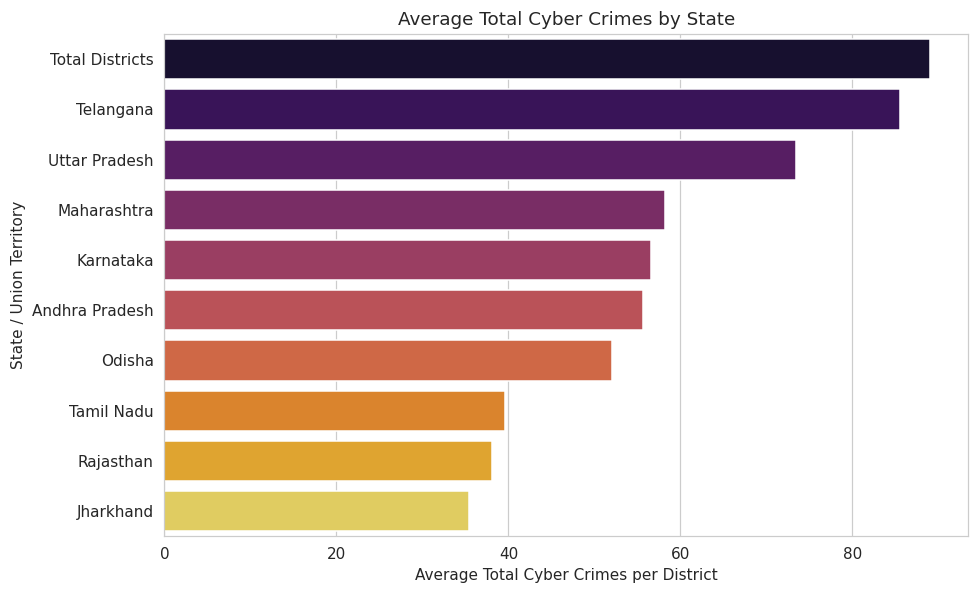

In [9]:
# Create a horizontal bar chart displaying the average total cyber crimes for the top 10 states
fig, ax = plt.subplots(figsize=(9, 5.5))

# Using the state_summary dataframe created in the previous step
top_10 = state_summary.head(10)
order = top_10.index

# Plotting the data
sns.barplot(x=top_10['Avg_Total_Crimes'], y=order, ax=ax, hue=order, palette='inferno', legend=False)

# Updated labels to match the actual crime data being plotted
ax.set_xlabel('Average Total Cyber Crimes per District')
ax.set_ylabel('State / Union Territory')
ax.set_title('Average Total Cyber Crimes by State')

plt.tight_layout()
plt.show()

### 5.2 Box Plot — Cyber Crimes Distribution by State

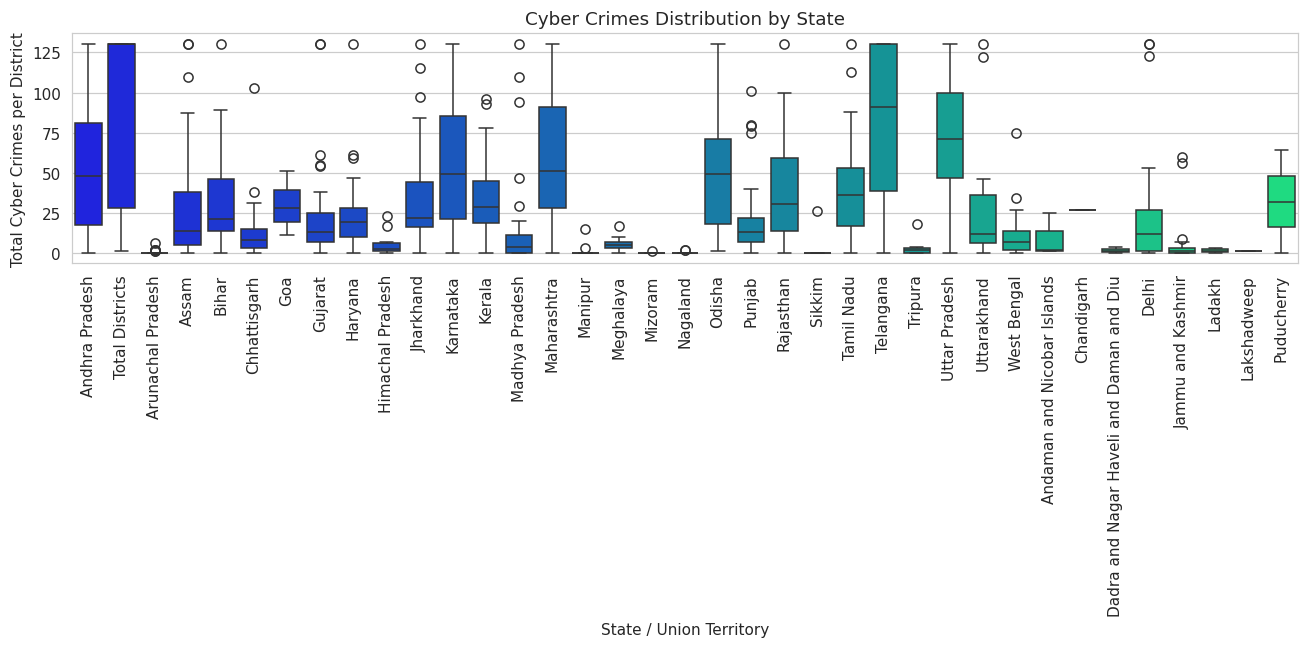

In [10]:
# Generate a box plot to compare the spread and median of cyber crimes across different states
fig, ax = plt.subplots(figsize=(12, 6))

# Plotting the distribution of total cyber crimes per district for each state
sns.boxplot(x='State/UT', y='Total Cyber Crimes (A+B+C) - Col. ( 51)', data=df, ax=ax, hue='State/UT', palette='winter', legend=False)

ax.set_xlabel('State / Union Territory')
ax.set_ylabel('Total Cyber Crimes per District')
ax.set_title('Cyber Crimes Distribution by State')

# Rotate x-axis labels so all 36 state names remain readable
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### 5.3 Scatter Plot — IT Act Offences vs Online Fraud by State

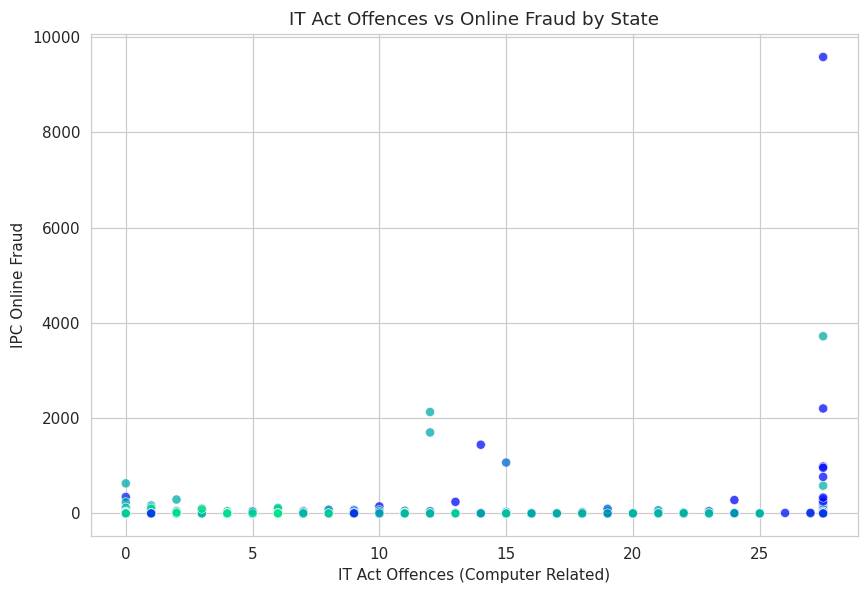

In [11]:
# Visualize the relationship between IT Act Offences and Online Fraud, color-coded by State
fig, ax = plt.subplots(figsize=(8, 5.5))

# Storing the long column names in variables to keep the plotting code clean
it_offences = 'A. Offences under I.T.Act - Computer Related Offences - Computer Related Offences (Total) (Col.5+Col.8+Col.9+Col.10+Col.11) - Col. ( 4)'
online_fraud = 'B. Offences under IPC (Involving Communication Devices as Medium/Target) r/w IT Act. - Fraud (Sec.420 r/w Sec.465,468-471 IPC) - Fraud (Sec.420 r/w Sec.465,468-471 IPC) (Total) (Col.29 to 33) - Col. ( 28)'

# Generate the scatter plot (legend is disabled because 36 states would clutter the plot)
sns.scatterplot(x=it_offences, y=online_fraud, hue='State/UT', data=df, ax=ax, alpha=0.75, palette='winter', legend=False)

ax.set_xlabel('IT Act Offences (Computer Related)')
ax.set_ylabel('IPC Online Fraud')
ax.set_title('IT Act Offences vs Online Fraud by State')

plt.tight_layout()
plt.show()

# 6. Time Series Analysis and Rolling Averages for Daily Cyber Crimes

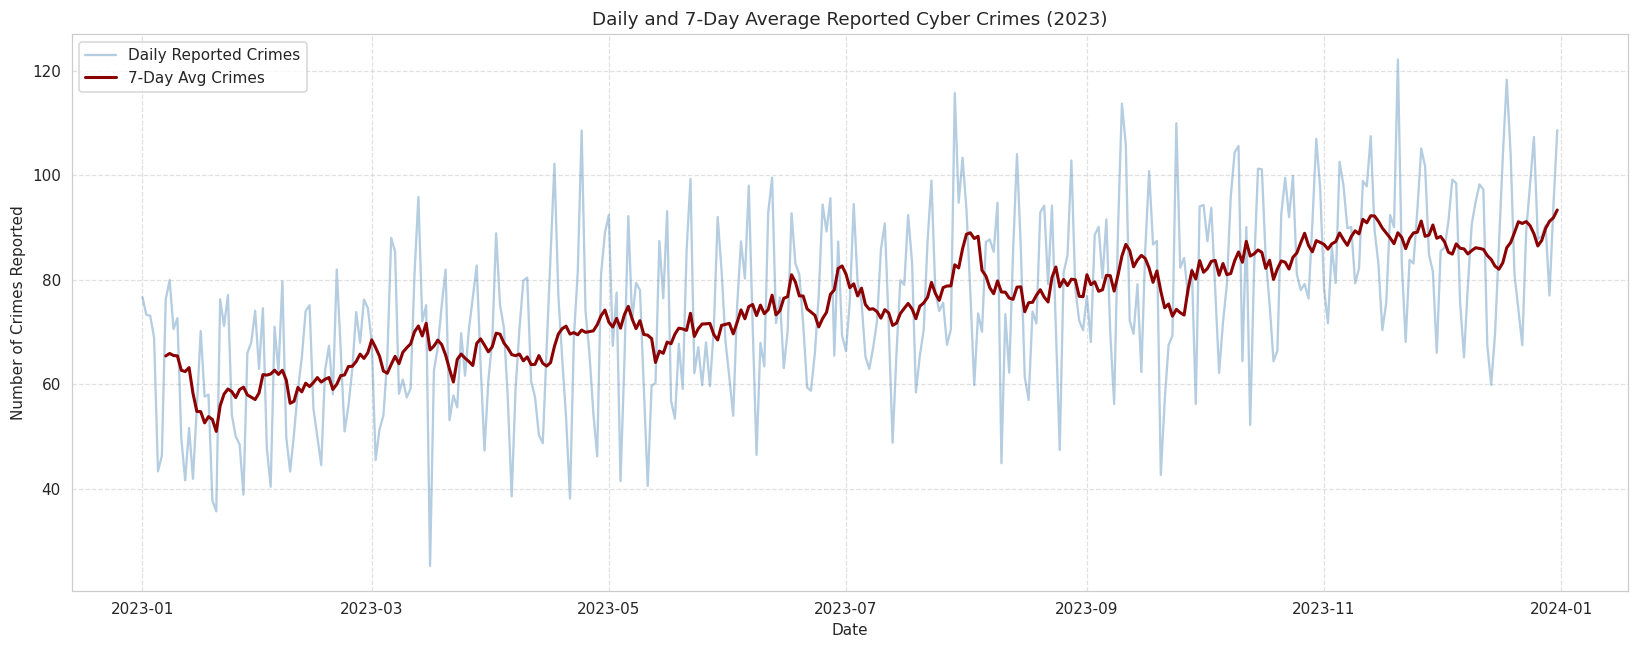

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Generate daily dates for the year 2023
dates = pd.date_range(start='2023-01-01', end='2023-12-31', freq='D')
np.random.seed(42)

# Simulate daily cyber crime reports (baseline + weekly seasonality + trend + noise)
base_crimes = 50 + 15 * np.sin(2 * np.pi * dates.dayofyear / 7)
trend = np.linspace(0, 30, len(dates))
noise = np.random.normal(loc=10, scale=10, size=len(dates))

# Calculate final daily crimes (using np.maximum to ensure no negative crime counts)
crimes = np.maximum(0, base_crimes + trend + noise)

# Create the DataFrame and set Date as the index
df = pd.DataFrame({'Date': dates, 'Reported_Crimes': crimes})
df.set_index('Date', inplace=True)

# Calculate the 7-day rolling average
df['7dayAvg'] = df['Reported_Crimes'].rolling(window=7).mean()

# Visualize the time series
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Reported_Crimes'], label='Daily Reported Crimes', alpha=0.4, color='steelblue')
plt.plot(df.index, df['7dayAvg'], label='7-Day Avg Crimes', linewidth=2, color='darkred')

plt.title('Daily and 7-Day Average Reported Cyber Crimes (2023)')
plt.xlabel('Date')
plt.ylabel('Number of Crimes Reported')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()